# 02 — Return distributions (`EXP-H01`)

## 1. Objective

Compare Gaussian and Student-t models of BTCUSDT log-return densities.

## 2. Hypothesis

A Student-t model is better calibrated than a Gaussian model at the 5-, 15-, and 60-minute horizons.

## 3. Null

The Student-t model adds no calibration value on that pre-registered family.

## 4. Information set

Each label uses only the close at the decision time and the close exactly one horizon later. No same-bar high or low, no future bar, and no local clock.

## 5. Dataset and version

`research/registry/datasets/btcusdt-1m.json`, loaded from `s3://trading-data-centheos` with AWS profile `trading`.

## 6. Data-quality checks

The dataset freeze counts duplicates, off-grid rows, bad prices, inconsistent OHLC, and missing minutes.

## 7. Label definition

`log(close[t + h]) - log(close[t])` only when both minute bars exist. A gap does not become a longer return.

## 8. Baseline

The nested baseline is the Gaussian model fit on the same training labels.

## 9. Model / method

Gaussian maximum likelihood. Student-t method of moments using mean, variance, and unbiased excess kurtosis. A non-positive excess kurtosis fails that window rather than silently reverting to a Gaussian.

## 10. Training / validation / test split

Rolling 24-month train and 6-month validation windows, stepped by 6 months. The final 12 calendar months are sealed. A label whose outcome falls beyond a block boundary leaves that block.

## 11. Experiment configuration

`research.protocol.H1_CONFIG`. Its digest is printed below.


In [1]:
from pathlib import Path
import os
import sys

root = Path.cwd().resolve()
while not (root / "research" / "__init__.py").is_file() and root != root.parent:
    root = root.parent
if not (root / "research" / "__init__.py").is_file():
    raise RuntimeError("open this notebook from the trading repository")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ["AWS_PROFILE"] = "trading"
os.environ["AWS_DEFAULT_REGION"] = "ap-southeast-2"
os.environ["DATA_STORE"] = "s3"
os.environ["S3_BUCKET"] = "trading-data-centheos"


In [2]:
import pandas as pd

from research.evaluate import align_to_frozen_dataset
from research.load import load_research_bars
from research.manifest import load_manifest
from research.protocol import H1_CONFIG

manifest_path = root / "research" / "registry" / "datasets" / "btcusdt-1m.json"
frozen = load_manifest(manifest_path)
bars, objects = load_research_bars(
    venue=H1_CONFIG["venue"],
    symbol=H1_CONFIG["symbol"],
    timeframe=H1_CONFIG["timeframe"],
    bucket=H1_CONFIG["bucket"],
    profile=H1_CONFIG["profile"],
    region=H1_CONFIG["region"],
)
if bars.empty:
    raise RuntimeError("BTCUSDT one-minute load returned no rows")
kept, report, appended = align_to_frozen_dataset(bars, frozen, objects)
print(
    f"frozen digest={frozen.digest} rows={report.rows_out} "
    f"collector_rows_after_freeze={appended}"
)


Excluded 63 collector rows after frozen end 2026-10-17T10:43:00+00:00; ohlcv/binance/BTCUSDT/1m/2026.parquet etag b67bbf4dddd1bcb2658bac4d361452ec -> 70d22afac39c46ab23af278f7dda0598, size 5482639 -> 5483978


frozen digest=c1192eca8fa673c386b4ff3aad751f4f2d4895e2b02d7b693a42aac1ecd28188 rows=3573284 collector_rows_after_freeze=63


## 12–17. Evaluation

The next cell reports the validation log-score comparison, the VaR coverage family, and an accept or reject of the null. The null is rejected when Student-t has a positive mean and median log-score advantage at every horizon. That choice is written to `EXP-H01` as the working benchmark. It is not a sealed confirmation and it does not retain the experiment. The VaR family is the median coverage p-value for each horizon and model, with a Bonferroni adjustment across the horizon-by-model grid. Failed windows are counted. There is no economic claim in H1. No ablation beyond the Gaussian nested model is claimed here.


In [3]:
from dataclasses import replace

from IPython.display import display

from research.evaluate import (
    evaluate_h1,
    h1_development_decision,
    h1_log_score_comparison,
    h1_var_coverage_family,
)
from research.protocol import H1_CONFIG
from research.registry import code_version, config_digest, load_record, save_record

print("H1 configuration", config_digest(H1_CONFIG))
evaluation = evaluate_h1(kept["close"], H1_CONFIG)
if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
comparison = h1_log_score_comparison(evaluation.scores)
coverage = h1_var_coverage_family(evaluation.scores)
verdict = h1_development_decision(comparison).iloc[0]
print(f"failed_or_skipped_windows={len(evaluation.failures)}")
print(f"decision: {verdict.null_decision} the null")
print(f"working benchmark: {verdict.benchmark}")
print(verdict.reason)
print("this validation pass is not a sealed confirmation")
record_path = root / "research" / "registry" / "EXP-H01.json"
current = load_record(record_path)
if current.sealed_access or current.decision == "retain":
    raise RuntimeError("development notebook cannot overwrite a sealed H1 decision")
save_record(
    record_path,
    replace(
        current,
        status="Exploratory",
        result=str(verdict.benchmark),
        decision="",
        dataset_id=frozen.dataset_id,
        dataset_digest=frozen.digest,
        code_version=code_version(root),
        config_digest=config_digest(H1_CONFIG),
        sealed_access=False,
        run_id="",
    ),
)
display(comparison)
display(coverage)


H1 configuration 5c06edef219302cfc2906f7a4b2ef4a1e643a36cfe7bc0e5b4b6ba74cbf48484


Research code version is dirty: cbb99ab50632f790fa9a2e41b032c7ce5f2e7bd6+dirty


failed_or_skipped_windows=0
decision: reject the null
working benchmark: student_t
Student-t log score beats Gaussian at every horizon
this validation pass is not a sealed confirmation


,horizon_minutes,mean_advantage,median_advantage,origins
0,5,0.180775,0.173121,7
1,15,0.172543,0.170449,7
2,60,0.163201,0.163492,7


,horizon_minutes,model,median_var_pvalue,bonferroni_var_pvalue
0,5,gaussian,0.000000e+00,0.000000e+00
1,5,student_t,0.000000e+00,0.000000e+00
2,15,gaussian,0.000000e+00,0.000000e+00
3,15,student_t,2.186240e-320,1.311744e-319
4,60,gaussian,0.000000e+00,0.000000e+00
5,60,student_t,6.278220e-139,3.766932e-138


## Development plots

These figures draw the validation scores from the cell above. They do not refit the models and they do not read the sealed test.

1. Student-t minus Gaussian mean log score at each origin. A point above zero means the Student-t scored that validation window more highly.
2. The same scores as levels, so the gap can be read against the score itself.
3. Share of validation returns below each model's 5% VaR. The horizontal line is the pre-registered 5% rate.
4. Model expected shortfall against the mean of the returns that breached its VaR. A point on the diagonal matches.


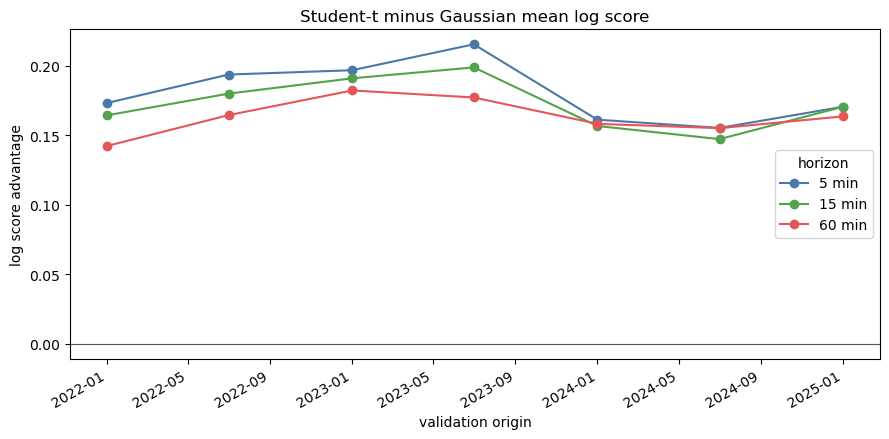

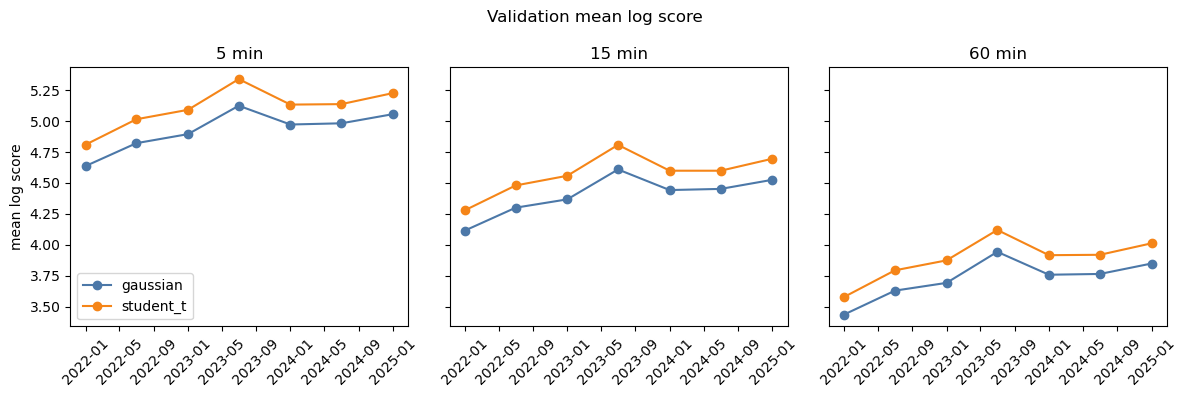

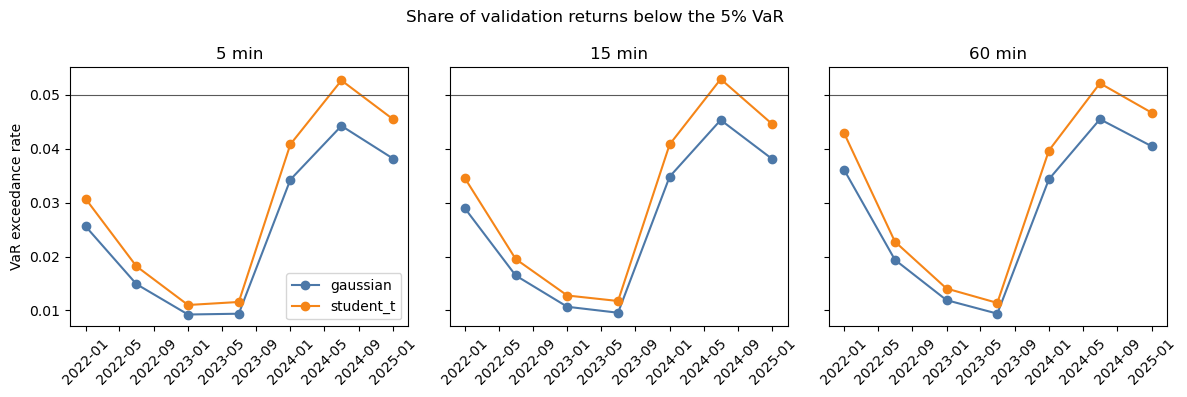

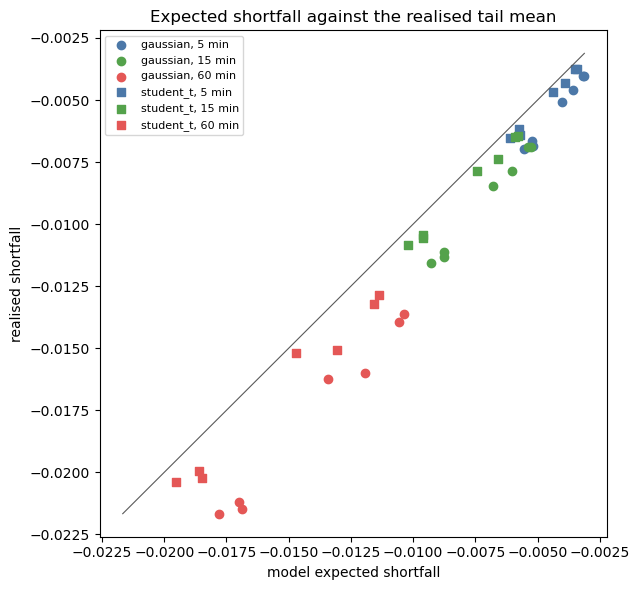

In [4]:
import matplotlib.pyplot as plt
import numpy as np

if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
scores = evaluation.scores.copy()
required = {
    "horizon_minutes",
    "origin",
    "model",
    "mean_log_score",
    "var_exceedance_rate",
    "expected_shortfall",
    "realised_shortfall",
}
missing = required - set(scores.columns)
if missing:
    raise RuntimeError(f"H1 scores are missing columns: {sorted(missing)}")
if not {"gaussian", "student_t"}.issubset(set(scores["model"])):
    raise RuntimeError(f"H1 plots need both models, found {sorted(scores['model'].unique())}")
scores["origin_date"] = pd.to_datetime(scores["origin"], format="%Y%m%d")
horizons = sorted(int(value) for value in scores["horizon_minutes"].unique())
model_color = {"gaussian": "#4c78a8", "student_t": "#f58518"}
horizon_color = {5: "#4c78a8", 15: "#54a24b", 60: "#e45756"}

advantage = scores.pivot_table(
    index=["horizon_minutes", "origin_date"],
    columns="model",
    values="mean_log_score",
    aggfunc="first",
).reset_index()
advantage["student_minus_gaussian"] = advantage["student_t"] - advantage["gaussian"]

fig, ax = plt.subplots(figsize=(9, 4.5))
for horizon in horizons:
    part = advantage.loc[advantage["horizon_minutes"] == horizon].sort_values("origin_date")
    ax.plot(
        part["origin_date"],
        part["student_minus_gaussian"],
        marker="o",
        color=horizon_color.get(horizon),
        label=f"{horizon} min",
    )
ax.axhline(0.0, color="0.35", linewidth=0.8)
ax.set_title("Student-t minus Gaussian mean log score")
ax.set_xlabel("validation origin")
ax.set_ylabel("log score advantage")
ax.legend(title="horizon")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(horizons), figsize=(12, 4), sharey=True)
for ax, horizon in zip(np.atleast_1d(axes), horizons):
    part = scores.loc[scores["horizon_minutes"] == horizon]
    for model in ("gaussian", "student_t"):
        series = part.loc[part["model"] == model].sort_values("origin_date")
        ax.plot(
            series["origin_date"],
            series["mean_log_score"],
            marker="o",
            color=model_color[model],
            label=model,
        )
    ax.set_title(f"{horizon} min")
    ax.tick_params(axis="x", labelrotation=45)
axes = np.atleast_1d(axes)
axes[0].set_ylabel("mean log score")
axes[0].legend()
fig.suptitle("Validation mean log score")
fig.tight_layout()
plt.show()

alpha = float(H1_CONFIG["var_alpha"])
fig, axes = plt.subplots(1, len(horizons), figsize=(12, 4), sharey=True)
for ax, horizon in zip(np.atleast_1d(axes), horizons):
    part = scores.loc[scores["horizon_minutes"] == horizon]
    for model in ("gaussian", "student_t"):
        series = part.loc[part["model"] == model].sort_values("origin_date")
        ax.plot(
            series["origin_date"],
            series["var_exceedance_rate"],
            marker="o",
            color=model_color[model],
            label=model,
        )
    ax.axhline(alpha, color="0.35", linewidth=0.8)
    ax.set_title(f"{horizon} min")
    ax.tick_params(axis="x", labelrotation=45)
axes = np.atleast_1d(axes)
axes[0].set_ylabel("VaR exceedance rate")
axes[0].legend()
fig.suptitle("Share of validation returns below the 5% VaR")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6))
for model, marker in (("gaussian", "o"), ("student_t", "s")):
    part = scores.loc[scores["model"] == model].dropna(subset=["realised_shortfall"])
    if part.empty:
        raise RuntimeError(f"{model} has no realised shortfall to plot")
    for horizon in horizons:
        window = part.loc[part["horizon_minutes"] == horizon]
        ax.scatter(
            window["expected_shortfall"],
            window["realised_shortfall"],
            marker=marker,
            color=horizon_color.get(horizon, "0.2"),
            label=f"{model}, {horizon} min",
        )
shortfall = scores.dropna(subset=["realised_shortfall"])
low = min(shortfall["expected_shortfall"].min(), shortfall["realised_shortfall"].min())
high = max(shortfall["expected_shortfall"].max(), shortfall["realised_shortfall"].max())
ax.plot([low, high], [low, high], color="0.35", linewidth=0.8)
ax.set_xlabel("model expected shortfall")
ax.set_ylabel("realised shortfall")
ax.set_title("Expected shortfall against the realised tail mean")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## Calibration diagnostics

These figures use the rolling validation windows. Re-run the evaluation cell after a kernel restart so the PIT quantiles are recorded. They do not read the sealed test.

1. PIT QQ. The diagonal is a uniform probability integral transform. A curve above the diagonal means too much probability was assigned to smaller returns. Faint lines are individual origins; the heavy line is their mean.
2. VaR coverage. The hit rate is the share of validation returns below the model's 5% VaR. The horizontal line is the pre-registered 5% rate.
3. Expected shortfall. Solid lines are the model ES. Dashed lines are the mean of the validation returns that breached that VaR.


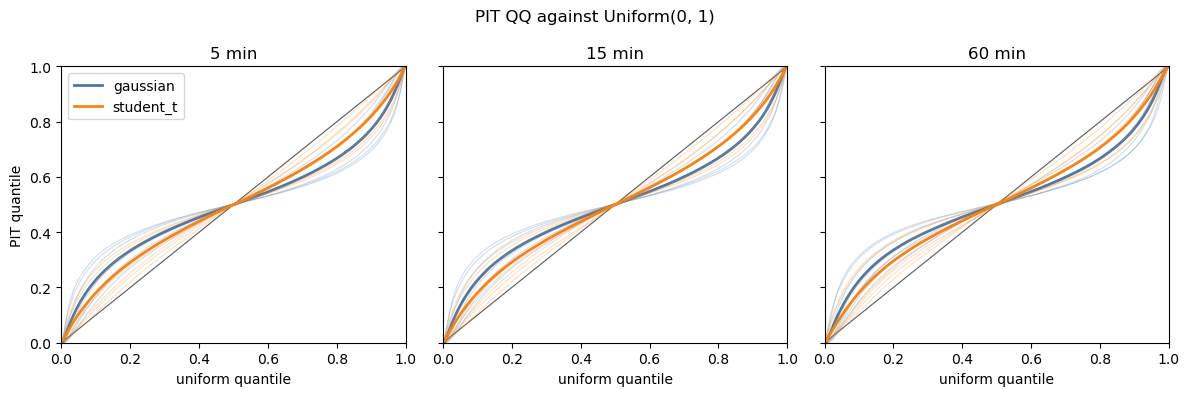

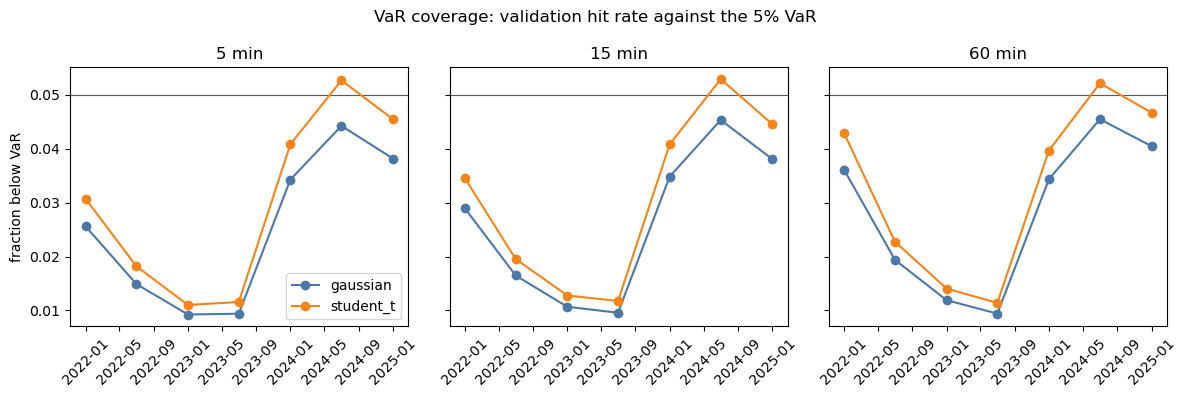

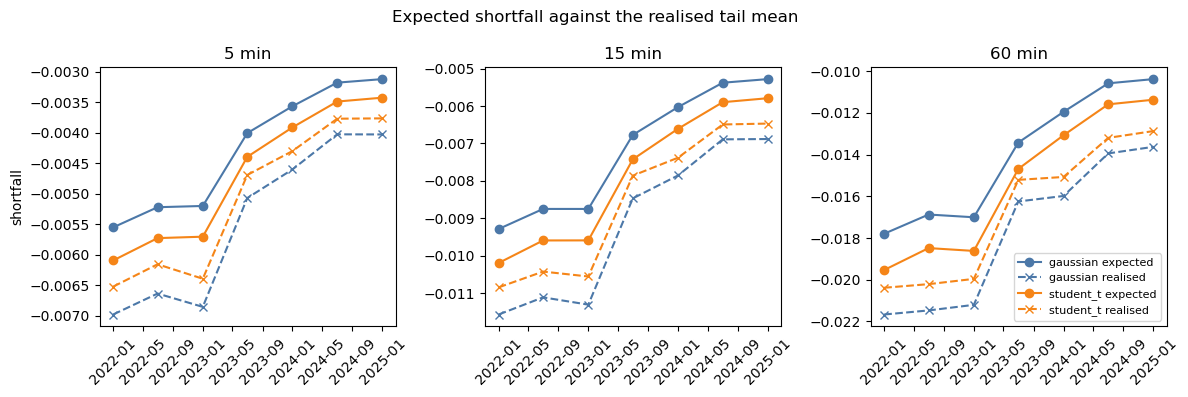

In [5]:
import matplotlib.pyplot as plt
import numpy as np

if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
if not hasattr(evaluation, "pit_qq"):
    raise RuntimeError("re-run the evaluation cell so it records PIT quantiles")
qq = evaluation.pit_qq.copy()
required_qq = {"horizon_minutes", "origin", "model", "theoretical", "empirical", "sealed_access"}
missing_qq = required_qq - set(qq.columns)
if missing_qq:
    raise RuntimeError(f"PIT QQ is missing columns: {sorted(missing_qq)}")
if bool(qq["sealed_access"].any()):
    raise RuntimeError("PIT QQ contains a sealed observation")
required_scores = {"horizon_minutes", "origin", "model", "var_exceedance_rate", "expected_shortfall", "realised_shortfall"}
missing_scores = required_scores - set(evaluation.scores.columns)
if missing_scores:
    raise RuntimeError(f"H1 scores are missing columns: {sorted(missing_scores)}")
scores = evaluation.scores.copy()
scores["origin_date"] = pd.to_datetime(scores["origin"], format="%Y%m%d")
horizons = sorted(int(value) for value in scores["horizon_minutes"].unique())
model_color = {"gaussian": "#4c78a8", "student_t": "#f58518"}
if not {"gaussian", "student_t"}.issubset(set(scores["model"])):
    raise RuntimeError(f"calibration plots need both models, found {sorted(scores['model'].unique())}")

fig, axes = plt.subplots(1, len(horizons), figsize=(12, 4), sharex=True, sharey=True)
for ax, horizon in zip(np.atleast_1d(axes), horizons):
    ax.plot([0, 1], [0, 1], color="0.35", linewidth=0.8)
    part = qq.loc[qq["horizon_minutes"] == horizon]
    for model in ("gaussian", "student_t"):
        model_part = part.loc[part["model"] == model]
        if model_part.empty:
            raise RuntimeError(f"no PIT QQ for {model} at {horizon} minutes")
        for _, origin_part in model_part.groupby("origin"):
            curve = origin_part.sort_values("theoretical")
            ax.plot(
                curve["theoretical"],
                curve["empirical"],
                color=model_color[model],
                alpha=0.25,
                linewidth=0.8,
            )
        mean_curve = (
            model_part.groupby("theoretical", as_index=False)["empirical"].mean().sort_values("theoretical")
        )
        ax.plot(
            mean_curve["theoretical"],
            mean_curve["empirical"],
            color=model_color[model],
            linewidth=2,
            label=model,
        )
    ax.set_title(f"{horizon} min")
    ax.set_xlabel("uniform quantile")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
axes = np.atleast_1d(axes)
axes[0].set_ylabel("PIT quantile")
axes[0].legend()
fig.suptitle("PIT QQ against Uniform(0, 1)")
fig.tight_layout()
plt.show()

alpha = float(H1_CONFIG["var_alpha"])
fig, axes = plt.subplots(1, len(horizons), figsize=(12, 4), sharey=True)
for ax, horizon in zip(np.atleast_1d(axes), horizons):
    part = scores.loc[scores["horizon_minutes"] == horizon]
    ax.axhline(alpha, color="0.35", linewidth=0.8)
    for model in ("gaussian", "student_t"):
        series = part.loc[part["model"] == model].sort_values("origin_date")
        ax.plot(
            series["origin_date"],
            series["var_exceedance_rate"],
            marker="o",
            color=model_color[model],
            label=model,
        )
    ax.set_title(f"{horizon} min")
    ax.tick_params(axis="x", labelrotation=45)
axes = np.atleast_1d(axes)
axes[0].set_ylabel("fraction below VaR")
axes[0].legend()
fig.suptitle("VaR coverage: validation hit rate against the 5% VaR")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(horizons), figsize=(12, 4), sharey=False)
for ax, horizon in zip(np.atleast_1d(axes), horizons):
    part = scores.loc[scores["horizon_minutes"] == horizon]
    for model in ("gaussian", "student_t"):
        series = part.loc[part["model"] == model].sort_values("origin_date")
        if series["realised_shortfall"].isna().any():
            raise RuntimeError(f"{model} at {horizon} minutes has a window with no VaR exceedances")
        ax.plot(
            series["origin_date"],
            series["expected_shortfall"],
            color=model_color[model],
            marker="o",
            label=f"{model} expected",
        )
        ax.plot(
            series["origin_date"],
            series["realised_shortfall"],
            color=model_color[model],
            marker="x",
            linestyle="--",
            label=f"{model} realised",
        )
    ax.set_title(f"{horizon} min")
    ax.tick_params(axis="x", labelrotation=45)
axes = np.atleast_1d(axes)
axes[0].set_ylabel("shortfall")
axes[-1].legend(fontsize=8)
fig.suptitle("Expected shortfall against the realised tail mean")
fig.tight_layout()
plt.show()


## Fitted densities

Each panel shows the development-sample log returns at one horizon. The curves are a Gaussian and a Student-t fit to that pooled sample. This is a picture of the shape, not the rolling-origin models scored above. Returns whose outcome falls in the sealed year are excluded. The top row shows the body of the distribution. The bottom row uses a log density scale and a wider return axis, covering all but the outer 0.001% of each tail, with room above the peak. Bar heights use the full sample size, so clipping the axis does not inflate the histogram.


5 min n=3047035 held_out=526244 gaussian_std=0.00206876 student_df=4.03
15 min n=3047025 held_out=526244 gaussian_std=0.00348342 student_df=4.05
60 min n=3046980 held_out=526244 gaussian_std=0.00677992 student_df=4.08


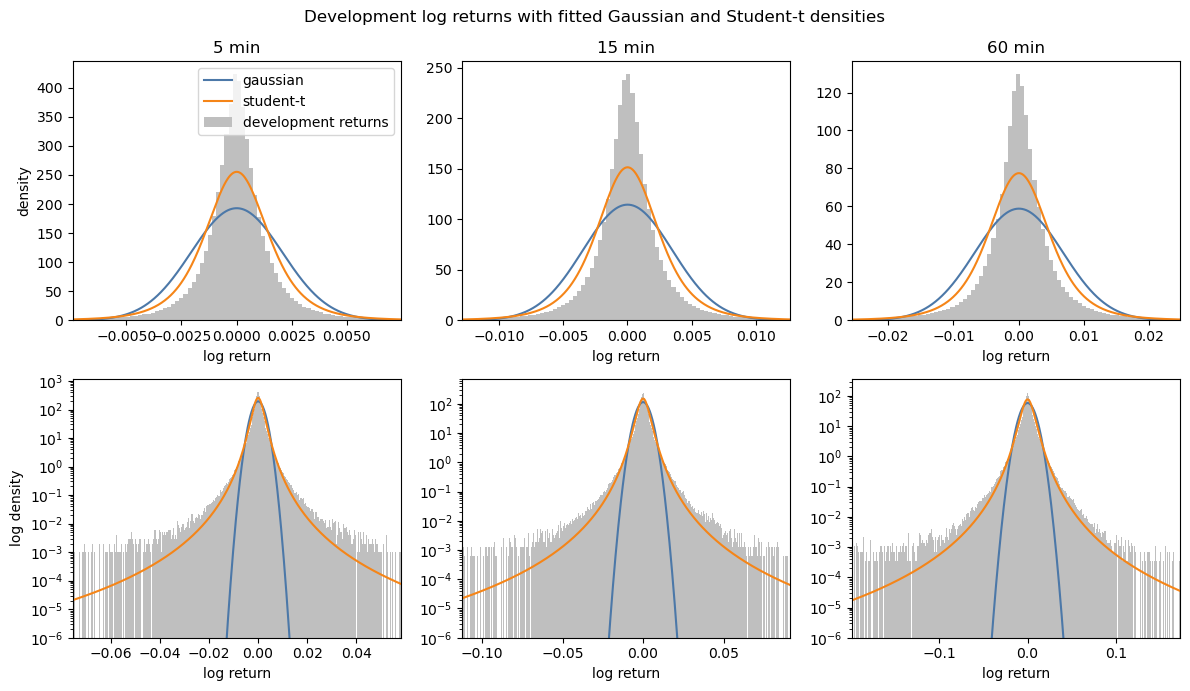

In [6]:
from research.distributions import fit_gaussian, fit_student_t
from research.returns import horizon_log_returns
from research.splits import development_returns

if evaluation.sealed_access:
    raise RuntimeError("development notebook read the sealed test")
fig, axes = plt.subplots(2, len(horizons), figsize=(12, 7))
for column, horizon in enumerate(horizons):
    built = horizon_log_returns(kept["close"], int(horizon))
    sample, held_out = development_returns(built.returns, int(horizon), evaluation.boundary)
    if held_out == 0:
        raise RuntimeError(f"{horizon}-minute plot held out no sealed labels")
    values = sample.to_numpy(dtype=float)
    gaussian = fit_gaussian(values)
    student = fit_student_t(values)
    body = np.quantile(values, [0.005, 0.995])
    tails = np.quantile(values, [0.00001, 0.99999])
    windows = ((body, False), (tails, True))
    print(
        f"{horizon} min n={len(values)} held_out={held_out} "
        f"gaussian_std={gaussian.variance ** 0.5:.6g} student_df={student.df:.2f}"
    )
    for row, (window, log_scale) in enumerate(windows):
        ax = axes[row, column]
        bin_width = (float(body[1]) - float(body[0])) / 80
        bins = int(np.ceil((float(window[1]) - float(window[0])) / bin_width))
        bins = min(max(bins, 80), 400)
        counts, edges = np.histogram(values, bins=bins, range=(float(window[0]), float(window[1])))
        width = np.diff(edges)
        density = counts / (len(values) * width)
        ax.bar(
            edges[:-1],
            np.where(density > 0, density, np.nan),
            width=width,
            align="edge",
            color="0.75",
            label="development returns",
        )
        grid = np.linspace(float(window[0]), float(window[1]), 500)
        gaussian_density = np.exp(gaussian.log_density(grid))
        student_density = np.exp(student.log_density(grid))
        ax.plot(grid, gaussian_density, color=model_color["gaussian"], label="gaussian")
        ax.plot(grid, student_density, color=model_color["student_t"], label="student-t")
        ax.set_xlim(window)
        if log_scale:
            ax.set_yscale("log")
            peak = max(
                float(np.nanmax(density)),
                float(np.nanmax(gaussian_density)),
                float(np.nanmax(student_density)),
            )
            ax.set_ylim(1e-6, peak * 3)
        if row == 0:
            ax.set_title(f"{horizon} min")
        if column == 0:
            ax.set_ylabel("log density" if log_scale else "density")
        ax.set_xlabel("log return")
axes[0, 0].legend()
fig.suptitle("Development log returns with fitted Gaussian and Student-t densities")
fig.tight_layout()
plt.show()


## 18. Result

The displayed comparison is a development result. It is not a confirmatory result.

## 19. Decision

The evaluation cell accepts or rejects the null and records the working benchmark on `EXP-H01`. Rejecting the null selects Student-t. Accepting it leaves Gaussian. That choice is not retention.

The next cell is the sealed confirmation. It fits on the development sample, scores the final 12 months once, and writes `sealed_access` with a run id. Run it only from a committed tree. A second run raises.




In [ ]:
from IPython.display import display

from research.evaluate import confirm_h1, h1_log_score_comparison
from research.registry import load_record

record_path = root / "research" / "registry" / "EXP-H01.json"
record = load_record(record_path)
if record.sealed_access or record.decision in {"retain", "reject"}:
    raise RuntimeError(
        f"H1 sealed test has already been used: decision={record.decision!r} "
        f"sealed_access={record.sealed_access}"
    )
confirmation = confirm_h1(
    kept["close"],
    record,
    dataset_id=frozen.dataset_id,
    dataset_digest=frozen.digest,
    root=root,
    record_path=record_path,
)
if not confirmation.record.sealed_access:
    raise RuntimeError("H1 confirmation did not record sealed access")
print(f"decision: {confirmation.record.decision}")
print(f"benchmark: {confirmation.record.result}")
print(f"status: {confirmation.record.status}")
print(f"run_id: {confirmation.record.run_id}")
print(f"sealed boundary: {confirmation.boundary.isoformat()}")
display(h1_log_score_comparison(confirmation.scores))
confirmation.scores

## 20. Reusable implementation

`research.returns`, `research.distributions`, `research.splits`, and `research.evaluate` hold the calculations. This notebook only loads data, calls them, and renders the result.

## 21. Next experiment

Review H1 before opening H2. If Student-t is rejected, H2 still proceeds against the retained Gaussian benchmark.
